### Part 2 (start in class)

First let's fit our supernova synthetic data from last time using GPR.

- The key ingredient in getting a good GPR fit is the choice of the kernel and its parameters.
- Radial-basis function kernel (aka squared-exponential kernel) is a standard choice in the GPR world.
- But check out what's available in the `kernels` submodule of [sklearn.gaussian_process](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.gaussian_process)
- Plot the expectation value of the fit as well as the resulting 1-$\sigma$ and 2-$\sigma$ contours.
- Interpret the results.

*Note*. To start with, feel free to tweak the hyperparameters manually. But, of course, a publication-quality result will require a cross-validation analysis.

The European Space Agency is considering new cosmology-related space mission. They ask you to figure out what science you can do with 10 times more measurement compared to what you have right now. That is: you want to clone your data. We've seen this earlier in the class, but now we can do much much better.
- Think about the pdf of these data in $z$.
- Using your GPR fit, generate a set of $\mu$ measurements that respects the statistical properties of the data you were given. 

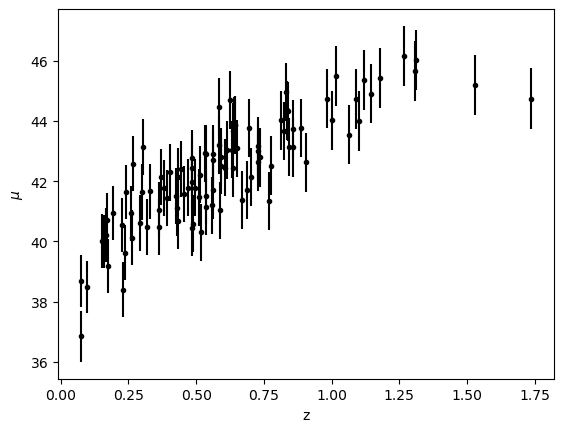

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import emcee, corner
from astropy.cosmology import LambdaCDM
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.neighbors import KernelDensity
from astroML.datasets import generate_mu_z

z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234)
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k')
plt.xlabel('z'); plt.ylabel(r'$\mu$');

In [9]:
kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(10.0, (1e-2, 1e2))
gp = GaussianProcessRegressor(kernel=kernel, alpha=dmu**2, n_restarts_optimizer=10)
gp.fit(z_sample[:, None], mu_sample)
print(gp.kernel_)

30.7**2 * RBF(length_scale=3.9)


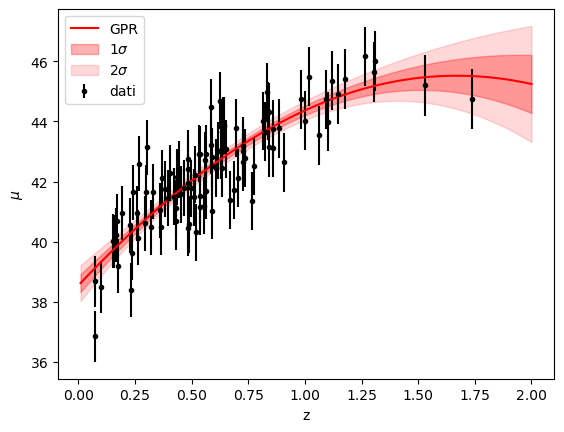

In [10]:
z_plot = np.linspace(0.01, 2, 1000)
mu_fit, sigma = gp.predict(z_plot[:, None], return_std=True)

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', label='dati')
plt.plot(z_plot, mu_fit, 'r', label='GPR')
plt.fill_between(z_plot, mu_fit-sigma, mu_fit+sigma, color='r', alpha=0.3, label=r'$1\sigma$')
plt.fill_between(z_plot, mu_fit-2*sigma, mu_fit+2*sigma, color='r', alpha=0.15, label=r'$2\sigma$')
plt.legend(); plt.xlabel('z'); plt.ylabel(r'$\mu$');

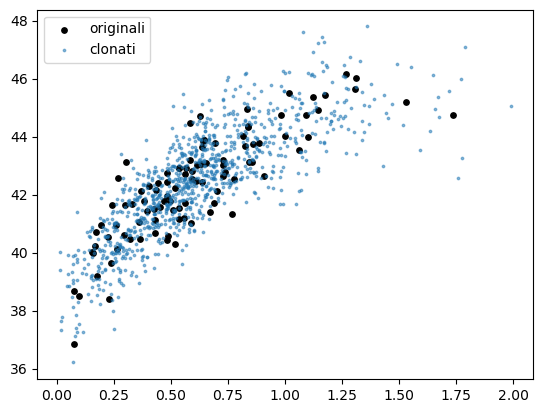

In [11]:
kde = KernelDensity(kernel='gaussian', bandwidth=0.1).fit(z_sample[:, None])
z_new = kde.sample(1000, random_state=0).ravel()
z_new = z_new[(z_new > 0.01) & (z_new < 2)]          # restiamo nel range dei dati

mu_g, s_g = gp.predict(z_new[:, None], return_std=True)
mu_new = np.random.normal(mu_g, np.sqrt(s_g**2 + np.interp(z_new, np.sort(z_sample), dmu[np.argsort(z_sample)])**2))

plt.scatter(z_sample, mu_sample, c='k', s=15, label='originali')
plt.scatter(z_new, mu_new, c='C0', s=3, alpha=0.5, label='clonati')
plt.legend();

- First, refresh your cosmology and write down the predicted relationship between the distance module $\mu$ and the redshift $\sigma$. *Hint* I always forget these things, my to-go reference is [Hogg (2010)](https://arxiv.org/abs/astro-ph/9905116). The answer is:

$$\mu = 5 \log \left( \frac{c/H_0} {10 {\rm pc}}(1+z)\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3+\Omega_\Lambda}} \right) $$

- Assuming a flat Universe,  we have a parametric non-linear model for $\mu(z)$ that depends on two parameters, the Hubble constant $H_0$ and the matter content of the Universe $\Omega_m$ (notice that $\Omega_\Lambda$ is not independent because $1 = \Omega_m + \Omega_\Lambda$)
- It's a very non-linear model. Fit it to the data, however you want to do it, using tecniques we've seen throughout the course. Some ideas:
    - Set up a Bayesian framework and MCMC and/or nested sampling. 
    - Set up a fully-connected neural network (see end of the class).

- What are the measured values of $H_0$ and $\Omega_m$. What are they errors? Are they correlated?
- How would a model without dark energy (i.e. $\Omega_m=1$) perform? Do these data contain evidence of dark energy? (Hint: this is a model selection problem)


In [12]:
def model(z, H0, Om):
    return LambdaCDM(H0=H0, Om0=Om, Ode0=1-Om).distmod(z).value

def LogPrior(theta):
    H0, Om = theta
    if 50 < H0 < 100 and 0.1 < Om < 1:
        return 0.0
    return -np.inf

def LogLikelihood(theta):
    mu_model = model(z_sample, *theta)
    return -0.5*np.sum(((mu_sample - mu_model)/dmu)**2 + np.log(2*np.pi*dmu**2))

def LogPosterior(theta):
    lp = LogPrior(theta)
    if not np.isfinite(lp):
        return -np.inf          # prior prima, così non valuto la likelihood fuori range
    return lp + LogLikelihood(theta)

100%|██████████| 5000/5000 [00:19<00:00, 250.45it/s]


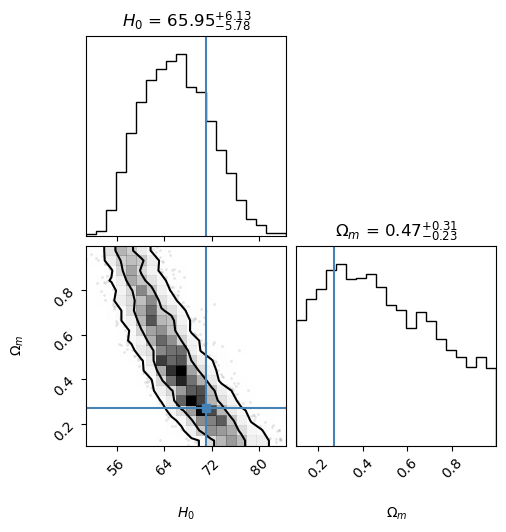

In [13]:
nwalkers, ndim, nsteps = 16, 2, 5000
p0 = np.array([70, 0.3]) + 1e-2*np.random.randn(nwalkers, ndim)
sampler = emcee.EnsembleSampler(nwalkers, ndim, LogPosterior)
sampler.run_mcmc(p0, nsteps, progress=True)

flat = sampler.get_chain(discard=1000, thin=15, flat=True)
corner.corner(flat, labels=[r"$H_0$", r"$\Omega_m$"], levels=[0.68, 0.95],
              show_titles=True, truths=[71, 0.27]);   # ATTENZIONE all'ordine

In [14]:
for name, s in zip(['H0', 'Om'], flat.T):
    lo, med, hi = np.percentile(s, [16, 50, 84])
    print(f"{name} = {med:.3f} +{hi-med:.3f} -{med-lo:.3f}")
print("correlazione H0-Om:", np.corrcoef(flat.T)[0, 1])

H0 = 65.953 +6.134 -5.784
Om = 0.467 +0.310 -0.233
correlazione H0-Om: -0.8545947520792004


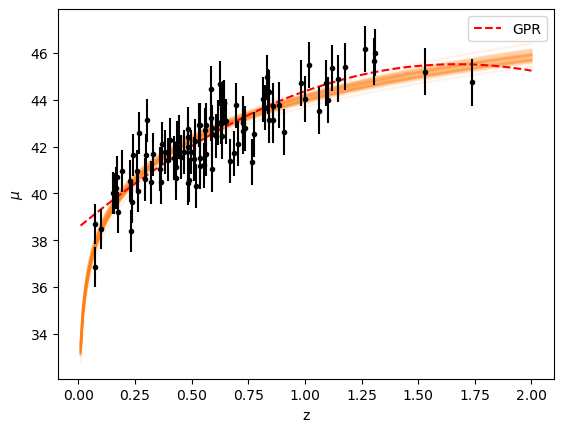

In [15]:
zz = np.linspace(0.01, 2, 200)
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', zorder=3)
for th in flat[np.random.randint(len(flat), size=50)]:
    plt.plot(zz, model(zz, *th), 'C1', alpha=0.1)
plt.plot(z_plot, mu_fit, 'r--', label='GPR')
plt.legend(); plt.xlabel('z'); plt.ylabel(r'$\mu$');

In [16]:
from scipy.optimize import minimize_scalar, minimize

def chi2(mu_mod): return np.sum(((mu_sample - mu_mod)/dmu)**2)

# EdS: Om=1, Ode=0, un solo parametro H0
res0 = minimize_scalar(lambda H0: chi2(LambdaCDM(H0, 1.0, 0.0).distmod(z_sample).value),
                       bounds=(50, 100), method='bounded')
chi2_0 = res0.fun
# ΛCDM piatto, 2 parametri
res1 = minimize(lambda t: -LogLikelihood(t), [70, 0.3], method='Nelder-Mead')
chi2_1 = chi2(model(z_sample, *res1.x))

N = len(z_sample)
BIC0 = chi2_0 + 1*np.log(N)
BIC1 = chi2_1 + 2*np.log(N)
print(f"chi2: EdS={chi2_0:.1f}, LCDM={chi2_1:.1f}")
print(f"BIC: EdS={BIC0:.1f}, LCDM={BIC1:.1f}, ΔBIC={BIC0-BIC1:.1f}")

chi2: EdS=94.2, LCDM=92.8
BIC: EdS=98.8, LCDM=102.0, ΔBIC=-3.2
